# Online Retail Sales Analysis & RFM Customer Segmentation     

In this project I looked at sales data from a UK online shop that sells gifts and home items. Most of its customers are other shops that buy in       bulk. The data goes from December 2009 to December 2011 and has more than 1 million rows.

What I wanted to find out:                  
1. How sales change from month to month    
2. Which countries and products bring in the most money   
3. What time of day customers place orders  
4. How much of the sales come from the top 20% of customers
5. How customers can be grouped by their buying behaviour (RFM), and what the business should do for each group

Note: I removed rows that had no Customer ID, so the results are based on about 85% of all sales.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Loading the data
 - The file has two sheets, one for each year. I joined them into one table and removed rows that were exact copies.

In [2]:
sheets=pd.read_excel(r"C:\Users\sreel\Downloads\online+retail+ii\online_retail_II.xlsx",sheet_name=None)

In [3]:
df = pd.concat(sheets.values(), ignore_index=True)
before = len(df)
df = df.drop_duplicates()
print("Duplicate rows removed:", before - len(df))

Duplicate rows removed: 34335


In [4]:
df

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom
...,...,...,...,...,...,...,...,...
1067366,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
1067367,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
1067368,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France
1067369,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France


In [5]:
df.info()

<class 'pandas.DataFrame'>
Index: 1033036 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1033036 non-null  object        
 1   StockCode    1033036 non-null  object        
 2   Description  1028761 non-null  object        
 3   Quantity     1033036 non-null  int64         
 4   InvoiceDate  1033036 non-null  datetime64[us]
 5   Price        1033036 non-null  float64       
 6   Customer ID  797885 non-null   float64       
 7   Country      1033036 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 84.3+ MB


## Cleaning the data
Here is what I did to clean the data:
- Filled missing product names using the name that matches the same StockCode
- Removed rows with no Customer ID
- Fixed the data types of some columns
- Removed cancelled orders (invoice numbers starting with "C") and rows where quantity or price was 0 or less
- Added a Revenue column (Quantity × Price)

In [6]:
df.isna().sum()

Invoice             0
StockCode           0
Description      4275
Quantity            0
InvoiceDate         0
Price               0
Customer ID    235151
Country             0
dtype: int64

In [7]:
desc_map = (df.dropna(subset=['Description'])
              .groupby('StockCode')['Description']
              .agg(lambda x: x.mode()[0]))

df['Description']=(df['Description'].fillna(df['StockCode'].map(desc_map)))
df['Description']=df['Description'].fillna('unknown')
df = df.dropna(subset=['Customer ID'])

In [8]:
df['Customer ID']=df['Customer ID'].astype('int64')

In [9]:
cols=['Invoice','StockCode','Description']
df[cols]=df[cols].astype(str)

In [10]:
df['Description']=df['Description'].str.strip()

In [11]:
# Count and remove cancelled invoices (start with "C")
cancelled = df[df['Invoice'].str.startswith('C')]
print("Cancelled rows:", len(cancelled))
df = df[~df['Invoice'].str.startswith('C')]

# Keep only real sales
df = df[(df['Quantity'] > 0) & (df['Price'] > 0)].copy()

# Create Revenue column
df['Revenue'] = df['Quantity'] * df['Price']
df.info()

Cancelled rows: 18390
<class 'pandas.DataFrame'>
Index: 779425 entries, 0 to 1067370
Data columns (total 9 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      779425 non-null  str           
 1   StockCode    779425 non-null  str           
 2   Description  779425 non-null  str           
 3   Quantity     779425 non-null  int64         
 4   InvoiceDate  779425 non-null  datetime64[us]
 5   Price        779425 non-null  float64       
 6   Customer ID  779425 non-null  int64         
 7   Country      779425 non-null  str           
 8   Revenue      779425 non-null  float64       
dtypes: datetime64[us](1), float64(2), int64(2), str(4)
memory usage: 97.6 MB


## Checking for outliers
 - Next I checked Quantity, Price and Revenue for very high or very low values. 
 - I used summary numbers, boxplots and the IQR method. The boxplots use a log scale because the values go from very small to very large.

In [12]:
df.describe()

,Quantity,InvoiceDate,Price,Customer ID,Revenue
count,779425.000000,779425,779425.000000,779425.000000,779425.000000
mean,13.489370,2011-01-03 01:44:42.593476,3.218488,15320.360461,22.291823
min,1.000000,2009-12-01 07:45:00,0.001000,12346.000000,0.001000
25%,2.000000,2010-07-02 14:39:00,1.250000,13971.000000,4.950000
50%,6.000000,2010-12-02 14:09:00,1.950000,15247.000000,12.480000
75%,12.000000,2011-08-01 13:44:00,3.750000,16794.000000,19.800000
max,80995.000000,2011-12-09 12:50:00,10953.500000,18287.000000,168469.600000
std,145.855814,NaN,29.676140,1695.692775,227.427075


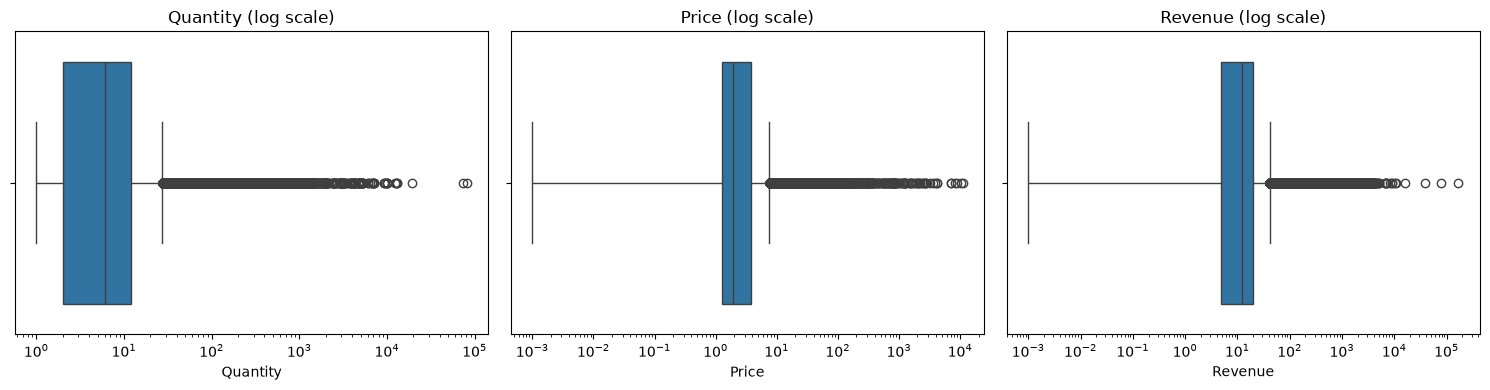

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['Quantity', 'Price', 'Revenue']):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_xscale('log')
    ax.set_title(f'{col} (log scale)')
plt.tight_layout()
plt.show()

In [14]:
for col in ['Quantity', 'Price', 'Revenue']:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    n = ((df[col] < Q1 - 1.5 * IQR) | (df[col] > Q3 + 1.5 * IQR)).sum()
    print(f"{col}: {n} outliers ({n / len(df) * 100:.1f}%)")

Quantity: 51119 outliers (6.6%)
Price: 65463 outliers (8.4%)
Revenue: 63562 outliers (8.2%)


In [15]:
df.nlargest(5, 'Quantity')[['Invoice', 'StockCode', 'Description', 'Quantity', 'Price', 'Revenue']]


,Invoice,StockCode,Description,Quantity,Price,Revenue
1065882,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.6
587080,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,77183.6
90857,497946,37410,BLACK AND WHITE PAISLEY FLOWER MUG,19152,0.10,1915.2
127166,501534,21099,SET/6 STRAWBERRY PAPER CUPS,12960,0.10,1296.0
127168,501534,21091,SET/6 WOODLAND PAPER PLATES,12960,0.10,1296.0


In [16]:
df.nlargest(5, 'Price')[['Invoice', 'StockCode', 'Description', 'Quantity', 'Price']]

,Invoice,StockCode,Description,Quantity,Price
135013,502263,M,Manual,1,10953.50
358639,524159,M,Manual,1,10468.80
74356,496115,M,Manual,1,8985.60
698843,551697,POST,POSTAGE,1,8142.75
129903,501766,M,Manual,1,6958.17


In [17]:
#  Remove the two huge orders that were cancelled immediately
df = df[~df['Invoice'].isin(['541431', '581483'])]

# Remove non-product stock codes
non_products = ['POST', 'M', 'C2', 'DOT', 'D', 'ADJUST', 'ADJUST2',
                'BANK CHARGES', 'TEST001', 'TEST002', 'AMAZONFEE']
removed = df['StockCode'].isin(non_products).sum()
df = df[~df['StockCode'].isin(non_products)]
print("Non-product rows removed:", removed)

Non-product rows removed: 2829


 - The IQR method marked about 7–8% of rows as outliers.
 - When I looked at them, most were just big orders, which is normal because many customers are wholesalers. So I kept those.

 - I only removed:
   1) Two huge orders (80,995 and 74,215 items) that were cancelled right after they were placed
   2) 2,829 rows that were not real products, like postage, bank charges and manual adjustments

# Sales Analysis

### Monthly sales
- I left out December 2011 because the data stops on 9 December, so that month is not complete.
- I have calculated and displayed Sales trend analysis as per months excluding December month

In [18]:
df['YearMonth'] = df['InvoiceDate'].dt.to_period('M')

In [19]:
monthly = df.groupby('YearMonth')['Revenue'].sum()
monthly.index = monthly.index.astype(str)

In [20]:
#  Remove December 2011 (partial month)
monthly = monthly[monthly.index != '2011-12']
m = monthly / 1e6   # revenue in millions


In [21]:
# Find highest and lowest months
high_month = m.idxmax()
low_month = m.idxmin()
high_pos = m.index.get_loc(high_month)   # position on the x-axis
low_pos = m.index.get_loc(low_month)


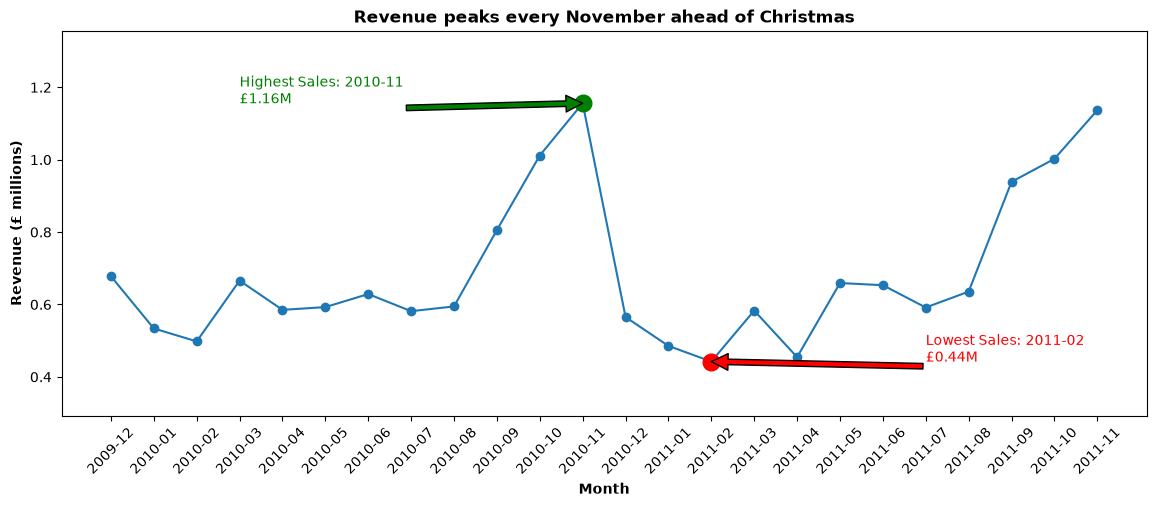

In [22]:
#  Draw the line chart
ax = m.plot(kind='line', marker='o', figsize=(14, 5))
plt.xticks(range(len(m)), m.index, rotation=45)

# Highlight highest (green) and lowest (red)
ax.plot(high_pos, m[high_month], marker='o', color='green', markersize=12)
ax.plot(low_pos, m[low_month], marker='o', color='red', markersize=12)

# Add labels

plt.annotate(
    f"Highest Sales: {high_month}\n£{m[high_month]:.2f}M",
    xy=(high_pos, m[high_month]),
    xytext=(high_pos - 8, m[high_month]),
      color="green",
    arrowprops=dict(facecolor="green")
)
plt.annotate(
    f"Lowest Sales: {low_month}\n£{m[low_month]:.2f}M",
    xy=(low_pos, m[low_month]),
    xytext=(low_pos + 5, m[low_month]),
      color="red",
    arrowprops=dict(facecolor="red")
)

plt.ylim(m.min() - 0.15, m.max() + 0.2)   # space for the labels
plt.title('Revenue peaks every November ahead of Christmas',fontweight='bold')
plt.xlabel('Month',fontweight='bold')
plt.ylabel('Revenue (£ millions)',fontweight='bold')
plt.show()

### Sales Trend Analysis Insights:
  
 - Sales start going up in September and are highest in November in both years (£1.16M in Nov 2010 and £1.14M in Nov 2011).
    
 - This makes sense because shops buy stock before Christmas. The lowest month was February 2011 with £0.44M.
    
  - So the business should get stock and offers ready before autumn.

### I wrote two small functions, `top10_by()` and `plot_top10()`, so the same code can be reused for countries and products instead of repeating it three times.

## Top Countries by Revenue

In [23]:
def top10_by(df, col):
    """Return the top 10 values of a column by total revenue (in £ millions)."""
    return (df.groupby(col)['Revenue'].sum() / 1e6) \
               .reset_index() \
               .sort_values(by='Revenue', ascending=False) \
               .head(10)


def plot_top10(df, y_col, title, ylabel):
    """Draw a horizontal bar chart of the top 10 by revenue."""
    sns.barplot(x='Revenue', y=y_col, data=df, hue=y_col,
                palette='Set2', legend=False, errorbar=None, orient='h')
    plt.title(title, fontweight='bold')
    plt.ylabel(ylabel, fontweight='bold')
    plt.xlabel('Revenue (£ millions)', fontweight='bold')
    plt.show()

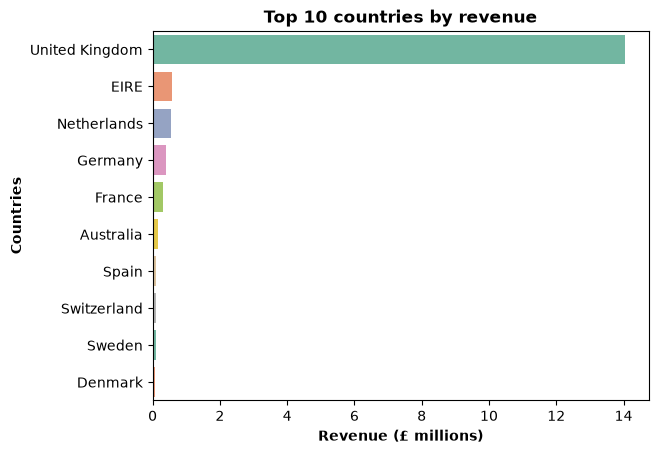

In [24]:
df_top10 = top10_by(df, 'Country')
plot_top10(df_top10, 'Country', 'Top 10 countries by revenue', 'Countries')

### Top 10 Countries by Revenue Insights:
  - The UK is far ahead of every other country, with £14.0M, which is about 83% of all sales. 
  - It is hard to see the other countries next to it, so I made a second chart without the UK.

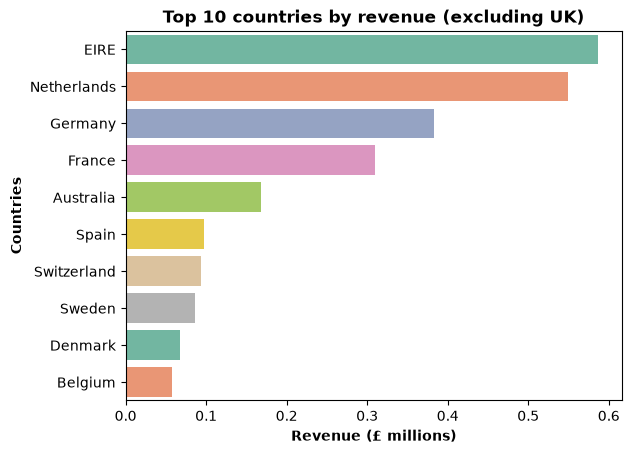

In [25]:
df_NUK = df[df['Country'] != 'United Kingdom']
df_top10_NUK = top10_by(df_NUK, 'Country')
plot_top10(df_top10_NUK, 'Country', 'Top 10 countries by revenue (excluding UK)', 'Countries')

### Top 10 Countries by Revenue (excluding UK) Insights:

 - Without the UK, the top countries are Ireland (shown as EIRE in the data) (£0.59M), the Netherlands (£0.55M), Germany (£0.38M) and France (£0.31M). 
        
 - These countries are all geographically close to the UK.

 - Since most sales come from just one country, growing sales in these countries could help the business.

### Do overseas customers place bigger orders than UK customers?
- I compared the value of each order for UK and non-UK customers.


In [26]:
# Total value of each order (one row per invoice)
order_value = df.groupby(['Invoice', 'Country'])['Revenue'].sum().reset_index()

uk = order_value[order_value['Country'] == 'United Kingdom']['Revenue']
non_uk = order_value[order_value['Country'] != 'United Kingdom']['Revenue']

print(f"UK orders:     {len(uk):,} | mean £{np.mean(uk):.0f} | median £{np.median(uk):.0f}")
print(f"Non-UK orders: {len(non_uk):,} | mean £{np.mean(non_uk):.0f} | median £{np.median(non_uk):.0f}")



UK orders:     33,359 | mean £421 | median £299
Non-UK orders: 3,233 | mean £860 | median £419


### Insight:
- Overseas customers place far fewer orders (3,233 vs 33,359), but each order is bigger (median £419 vs £299).
- This makes sense: overseas buyers pay more for shipping, so they order in bulk less often.
- Overseas customers are valuable, which supports growing sales in nearby European countries.

## Top Products by Revenue

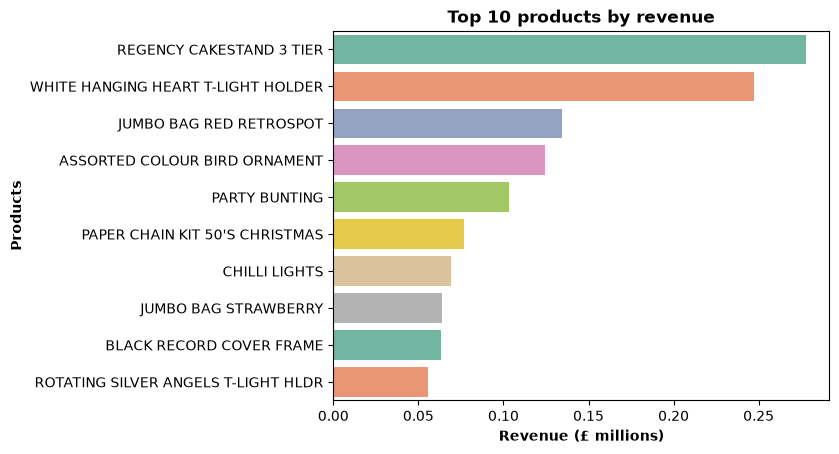

In [27]:
df_top10_pro = top10_by(df, 'Description')
plot_top10(df_top10_pro, 'Description', 'Top 10 products by revenue', 'Products')

### Top Products by Revenue Insights:

 - The best-selling product is the Regency Cakestand 3 Tier (£0.28M), and second is the White Hanging Heart T-Light Holder (£0.25M). 
        
 - Most of the top 10 are home decorations, bags, party items and Christmas items.

 - These products should always be kept in stock, especially before the busy months.

## What time customers order
 - I counted the number of orders in each hour of the day.

In [28]:
df['hour'] = df['InvoiceDate'].dt.strftime('%H:00')


In [29]:
orders_by_hour = df.groupby('hour')['Invoice'].nunique().reset_index(name='Orders')
orders_by_hour['Orders'] = pd.to_numeric(orders_by_hour['Orders'])
orders_by_hour = orders_by_hour.sort_values('hour')

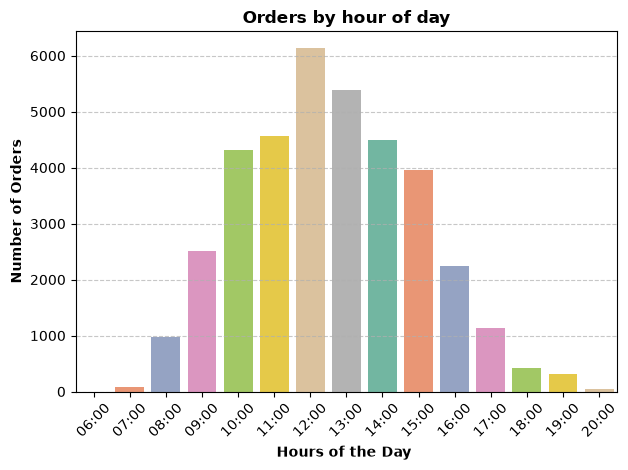

In [30]:
#  Plot directly with Seaborn
sns.barplot(
    y='Orders',
    x='hour', 
    data=orders_by_hour, 
    estimator=sum, 
    errorbar=None,
    hue='hour',
    legend=False,
    palette='Set2',
 
)
plt.title('Orders by hour of day',fontweight='bold')
plt.grid(axis="y", linestyle="--",
alpha=0.7)
plt.xlabel('Hours of the Day ',fontweight='bold')
plt.ylabel('Number of Orders',fontweight='bold')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Orders by Hour Insights:
 - Orders start at around 8:00, are highest at 12:00 (6,129 orders), and most come in between 10:00 and 15:00.
        
 - There are very few orders after 18:00, which fits with customers being businesses that order during work hours.

 - The best time to send emails or offers would be late morning, just before the lunchtime peak.

## Top 20% of customers
 - I wanted to check if a small group of customers brings in most of the money (the 80/20 rule). 
 - I ranked all customers by how much they spent.
 - I have also extracted unique customers who are not repeated
 - I have also calculated Top 20% Customers Revenue Share

In [31]:
Customers_revenue_sum=(df.groupby('Customer ID')['Revenue'].sum())

In [32]:
top_Sorted_customers_df=Customers_revenue_sum.reset_index().sort_values(by='Revenue', ascending=False).reset_index(drop=True)

In [33]:
# Calculate the cumulative percentage
top_Sorted_customers_df['Cumulative_Percentage'] = (top_Sorted_customers_df['Revenue'].cumsum() / top_Sorted_customers_df['Revenue'].sum()) * 100

In [34]:
total_unique_customers=df['Customer ID'].nunique()

In [35]:
top_20_customers = int(total_unique_customers * 0.2)

In [36]:
#top 20% customers
top_customers_df=top_Sorted_customers_df.head(top_20_customers)


In [37]:
top_share = top_customers_df['Revenue'].sum() / top_Sorted_customers_df['Revenue'].sum() * 100
print(f"Top 20% of customers ({top_20_customers}) generate {top_share:.1f}% of total revenue")

Top 20% of customers (1170) generate 76.9% of total revenue


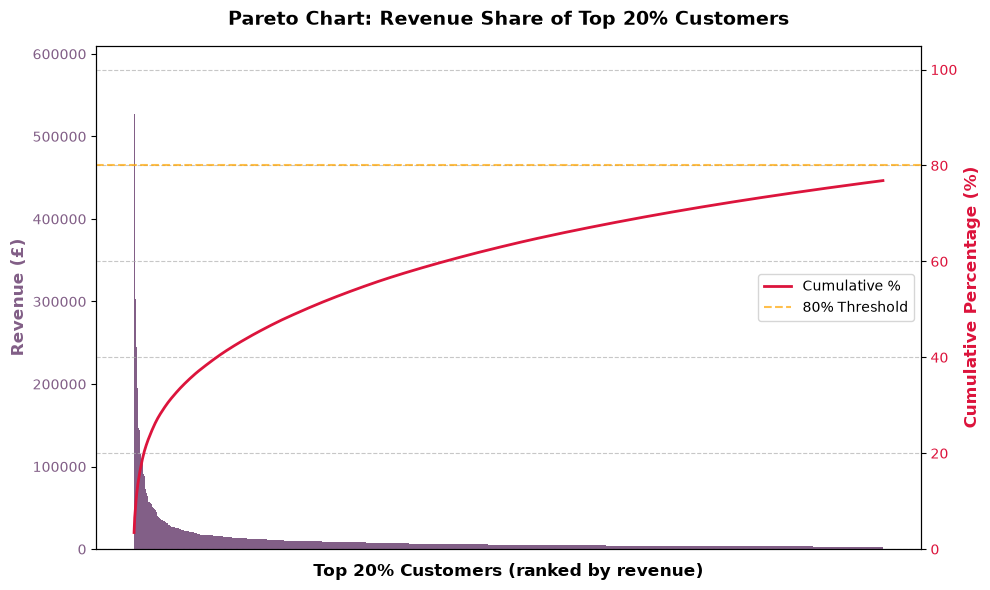

In [38]:

# Set up the plotting figure and primary axis (for bars)
fig, ax1 = plt.subplots(figsize=(10, 6))


x = range(len(top_customers_df))   

# Plot the bars on the primary y-axis
color1 = 'xkcd:dusty purple'

ax1.bar(x, top_customers_df['Revenue'], color=color1,width=1.0) # heights from top_customers_df, no black edges
ax1.set_xlabel('Top 20% Customers (ranked by revenue)', fontsize=12, labelpad=10,fontweight='bold')
ax1.set_ylabel('Revenue (£)', color=color1, fontsize=12, fontweight='bold')
ax1.tick_params(axis='y', labelcolor=color1)
ax1.set_xticks([])                       
ax1.set_title('Pareto Chart: Revenue Share of Top 20% Customers', fontsize=14, pad=15,fontweight='bold')   

#  Create a secondary y-axis for the cumulative percentage line
ax2 = ax1.twinx()
color2 = 'crimson'
ax2.plot(x, top_customers_df['Cumulative_Percentage'], color=color2, linewidth=2, label='Cumulative %')   
ax2.set_ylabel('Cumulative Percentage (%)', color=color2, fontsize=12,fontweight='bold')
ax2.tick_params(axis='y', labelcolor=color2)
ax2.set_ylim(0, 105)  # Leave room at the top


#  Add an 80% reference threshold line to easily spot the "vital few"
ax2.axhline(80, color='orange', linestyle='--', alpha=0.7, label='80% Threshold')
ax2.legend(loc='center right')

# Display the chart
plt.grid(axis="y", linestyle="--",
alpha=0.7)
plt.tight_layout()
plt.show()

### Revenue Share of Top 20% Customers Insights:

 - The top 20% of customers (1,170 out of 5,852) bring in 76.9% of all sales. 
        
 - That is very close to the 80/20 rule. The red line goes up very fast at the start, 
      which shows that a few customers spend a lot more than everyone else.

 - The business should try hard to keep these customers, for example with discounts or special offers or putting limited sale on                             some specific products which are most likely the products which customers are frequently buying.
    
 - By doing this Customers who are frequent won't be going away and in this way we are keeping our sales increasing or at least stable                         instead of decreasing

In [39]:
snapshot_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)
print(snapshot_date)

2011-12-10 12:50:00


### I calculated Recency, Frequency and Monetary for each customer, using 10 December 2011 as the reference date.

## Calculate R, F, and M together

In [40]:
rfm = df.groupby('Customer ID').agg(
    Recency=('InvoiceDate', lambda x: (snapshot_date - x.max()).days),
    Frequency=('Invoice', 'nunique'),
    Monetary=('Revenue', 'sum')
).reset_index()

## we are performing:
- groupby('Customer ID') makes one group per customer.
- Recency: finds the customer’s latest purchase date (x.max()), subtracts it from “today,” and turns the result into days (.days).
- Frequency: counts unique invoices (nunique). Use unique because one order has many rows, one per product. Counting rows would give the number of products, not orders.
- Monetary: adds up all their Revenue.

## Check the result

In [41]:
print(rfm.shape)
print(rfm.head())

(5852, 4)
   Customer ID  Recency  Frequency  Monetary
0        12346      529          2    169.36
1        12347        2          8   4921.53
2        12348       75          5   1658.40
3        12349       19          3   3678.69
4        12350      310          1    294.40


In [42]:
rfm.describe()

,Customer ID,Recency,Frequency,Monetary
count,5852.000000,5852.000000,5852.000000,5852.000000
mean,15319.707109,200.267772,6.252905,2874.731637
std,1714.929942,208.531131,12.749400,14108.719406
min,12346.000000,1.000000,1.000000,2.900000
25%,13837.750000,25.750000,1.000000,339.242500
50%,15320.500000,95.000000,3.000000,855.580000
75%,16802.250000,379.000000,7.000000,2237.292500
max,18287.000000,739.000000,373.000000,580987.040000


## What I have checked:

- Number of rows = 5,852, the same as the number of unique customers from the top-20% analysis. 
- Recency minimum is 1, and nothing is negative. 
- Monetary has no negative values. This should be true, because I already removed cancellations. 

#  Statistical analysis

## Statistical analysis of Recency, Frequency and Monetary
- Before giving scores, I looked at how R, F and M are spread out, using NumPy for the summary statistics.

In [43]:
summary = {}

for col in ['Recency', 'Frequency', 'Monetary']:
    values = rfm[col].to_numpy()          # turn the column into a NumPy array
    summary[col] = {
        'Mean': np.mean(values),
        'Median': np.median(values),
        'Std': np.std(values),
        'Min': np.min(values),
        '90th percentile': np.percentile(values, 90),
        'Max': np.max(values)
    }

summary_df = pd.DataFrame(summary).round(1)
summary_df

,Recency,Frequency,Monetary
Mean,200.3,6.3,2874.7
Median,95.0,3.0,855.6
Std,208.5,12.7,14107.5
Min,1.0,1.0,2.9
90th percentile,531.0,13.0,5374.9
Max,739.0,373.0,580987.0


### Insights:
- For all three, the **mean is much higher than the median**. For example, the average customer spent £2,875, but the middle customer spent only £856.
- This means a small number of very big customers pull the average up. The data is **right-skewed**.
- The top 10% of customers each spent more than £5,375, and the median customer placed only 3 orders.
- This matches the 80/20 finding: most revenue comes from a small group of customers.

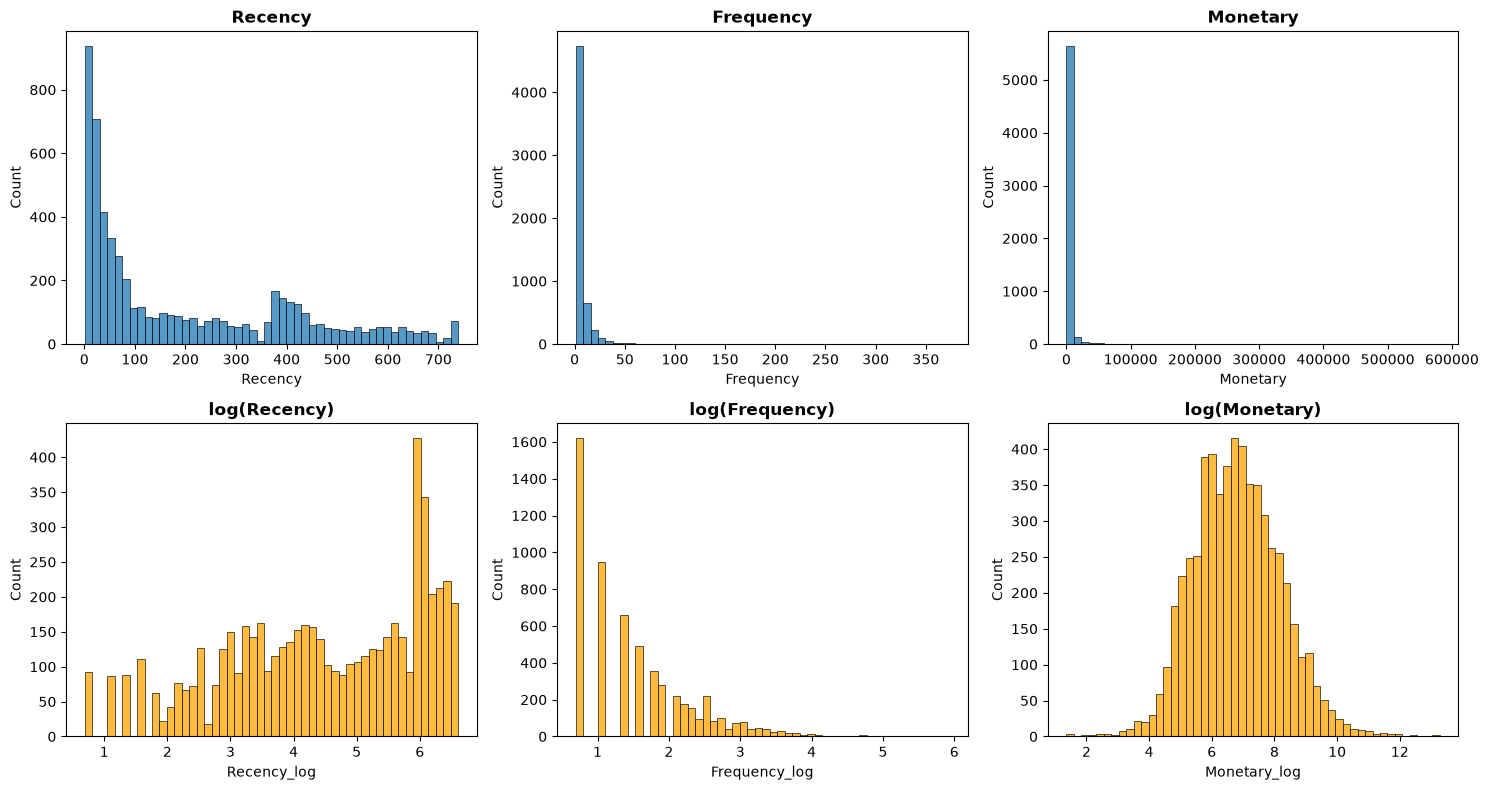

Recency       0.893820
Frequency    12.039959
Monetary     26.121112
dtype: float64
Recency_log     -0.485608
Frequency_log    1.002045
Monetary_log     0.250415
dtype: float64


In [44]:
rfm['Recency_log'] = np.log1p(rfm['Recency'])
rfm['Frequency_log'] = np.log1p(rfm['Frequency'])
rfm['Monetary_log'] = np.log1p(rfm['Monetary'])

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

# before log
sns.histplot(rfm['Recency'], bins=50, ax=axes[0, 0])
sns.histplot(rfm['Frequency'], bins=50, ax=axes[0, 1])
sns.histplot(rfm['Monetary'], bins=50, ax=axes[0, 2])

# after log
sns.histplot(rfm['Recency_log'], bins=50, ax=axes[1, 0], color='orange')
sns.histplot(rfm['Frequency_log'], bins=50, ax=axes[1, 1], color='orange')
sns.histplot(rfm['Monetary_log'], bins=50, ax=axes[1, 2], color='orange')


axes[0, 0].set_title('Recency', fontweight='bold')
axes[0, 1].set_title('Frequency', fontweight='bold')
axes[0, 2].set_title('Monetary', fontweight='bold')
axes[1, 0].set_title('log(Recency)', fontweight='bold')
axes[1, 1].set_title('log(Frequency)', fontweight='bold')
axes[1, 2].set_title('log(Monetary)', fontweight='bold')

plt.tight_layout()
plt.show()

print(rfm[['Recency', 'Frequency', 'Monetary']].skew())
print(rfm[['Recency_log', 'Frequency_log', 'Monetary_log']].skew())

### Insights:
- Skewness shows how lopsided the data is. A value near 0 means balanced; a big positive value means a long tail of very high values.
- Monetary (26.1) and Frequency (12.0) are **extremely skewed**: most customers are small, and a few are huge.
- After a log transform (`np.log1p`), Monetary drops to 0.25, so the shape becomes much more balanced and easier to see.
- Because the data is so skewed, I used **quintiles (`pd.qcut`)** for the RFM scores. This puts the same number of customers in each score group, instead of using equal-width ranges where almost everyone would land in the lowest group.

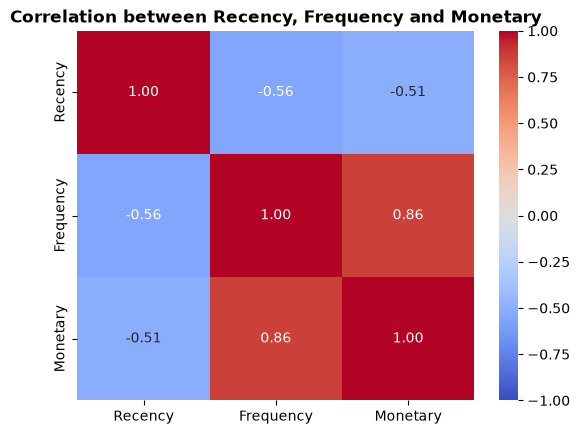

In [45]:
corr = rfm[['Recency', 'Frequency', 'Monetary']].corr(method='spearman')

sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt='.2f')
plt.title('Correlation between Recency, Frequency and Monetary', fontweight='bold')
plt.show()

### Insights:
- I used **Spearman correlation**, which compares rankings instead of raw values, so it works better for skewed data.
- **Frequency and Monetary are strongly related (0.86):** customers who order more often also spend more in total.
- **Recency is negatively related to both (-0.56 and -0.51):** customers who haven't ordered for a long time usually ordered less and spent less.
- So the three measures mostly agree with each other, which is why the RFM segments are clear and easy to explain.

# Recency score

In [46]:
rfm['R_Score'] = pd.qcut(rfm['Recency'], q=5, labels=[5, 4, 3, 2, 1])

## we are calculating:
- pd.qcut(..., q=5) splits customers into 5 equal groups.
- labels=[5, 4, 3, 2, 1] gives the group with the fewest days a 5.

# Frequency score

In [47]:
rfm['F_Score'] = pd.qcut(rfm['Frequency'].rank(method='first'), q=5, labels=[1, 2, 3, 4, 5])

## Why we used rank(method='first')?
- Many customers ordered exactly once, often more than 20% of them.
-  Without using this , qcut can’t split all those identical “1"s into separate groups, and you’d get an error like **“Bin edges must be unique.”** Ranking gives every customer a unique position, so the split works.

# Monetary score

In [48]:
rfm['M_Score'] = pd.qcut(rfm['Monetary'], q=5, labels=[1, 2, 3, 4, 5])

### Higher spending gets a higher score (1 = lowest, 5 = highest), so the labels count up normally.

# Combine the scores

In [49]:
rfm['RFM_Score'] = (rfm['R_Score'].astype(str) +
                    rfm['F_Score'].astype(str) +
                    rfm['M_Score'].astype(str)) 

R = rfm['R_Score'].astype(int)
F = rfm['F_Score'].astype(int)
M = rfm['M_Score'].astype(int)

conditions = [
    (R >= 4) & (F >= 4),
    (R >= 3) & (F >= 3),
    (R >= 4) & (F <= 2),
    (R <= 2) & (F >= 3),
    (R <= 2) & (F <= 2)
]
segments = ['Champions', 'Loyal', 'New Customers', 'At Risk', 'Lost']

rfm['Segment'] = np.select(conditions, segments, default='Need Attention')
print(rfm['Segment'].value_counts())
rfm.head()

Segment
Lost              1509
Champions         1476
Loyal             1207
At Risk            828
New Customers      450
Need Attention     382
Name: count, dtype: int64


,Customer ID,Recency,Frequency,Monetary,Recency_log,Frequency_log,Monetary_log,R_Score,F_Score,M_Score,RFM_Score,Segment
0,12346,529,2,169.36,6.272877,1.098612,5.137914,1,2,1,121,Lost
1,12347,2,8,4921.53,1.098612,2.197225,8.501578,5,4,5,545,Champions
2,12348,75,5,1658.40,4.330733,1.791759,7.414211,3,4,4,344,Loyal
3,12349,19,3,3678.69,2.995732,1.386294,8.210584,5,3,5,535,Loyal
4,12350,310,1,294.40,5.739793,0.693147,5.688330,2,1,2,212,Lost


### what we have done here is:
- Customer 12347 bought 2 days ago, so R = 5 (best). They placed 8 orders and spent £4,921, giving F = 4 and M = 5 and finally it goes as Score is 545 
- Customer 12346 last bought 529 days ago, so R = 1 (worst) and Score 121
- Each score group has about 1,170 customers.
-  Recency is slightly uneven (1,164, 1,173, 1,155) because many customers share the same number of days, so they can’t be split exactly.
-  Each Customer is labelled using R-score,F-score
-  np.select checks the rules in order and so a customer who matches more than one rule gets the first matching label.
-  The reason Why Champions comes before Loyal:**" a customer with R = 5 and F = 5 matches both rules, but should be a Champion."**
-  Customers who don’t match any rule are labelled **Need Attention.**

In [50]:
seg = rfm.groupby('Segment').agg(
    Customers=('Customer ID', 'count'),
    Revenue=('Monetary', 'sum'),
    Avg_Recency=('Recency', 'mean'),
    Avg_Frequency=('Frequency', 'mean'),
    Avg_Monetary=('Monetary', 'mean')
)
seg['Customer_%'] = seg['Customers'] / seg['Customers'].sum() * 100
seg['Revenue_%'] = seg['Revenue'] / seg['Revenue'].sum() * 100
seg.sort_values('Revenue', ascending=False).round(1)

,Customers,Revenue,Avg_Recency,Avg_Frequency,Avg_Monetary,Customer_%,Revenue_%
Segment,,,,,,,
Champions,1476,11816450.3,20.4,15.6,8005.7,25.2,70.2
Loyal,1207,2421467.1,78.2,5.4,2006.2,20.6,14.4
At Risk,828,1516485.1,367.9,5.0,1831.5,14.1,9.0
Lost,1509,619589.2,457.0,1.2,410.6,25.8,3.7
New Customers,450,247942.3,28.2,1.5,551.0,7.7,1.5
Need Attention,382,200995.5,106.5,1.4,526.2,6.5,1.2


# Check the result

In [51]:
rfm[['R_Score', 'F_Score', 'M_Score']].apply(pd.Series.value_counts)

,R_Score,F_Score,M_Score
1,1164,1171,1171
2,1173,1170,1170
3,1155,1170,1170
4,1174,1170,1170
5,1186,1171,1171


## A Bar Chart to compare % of customers with % of revenue for each segment

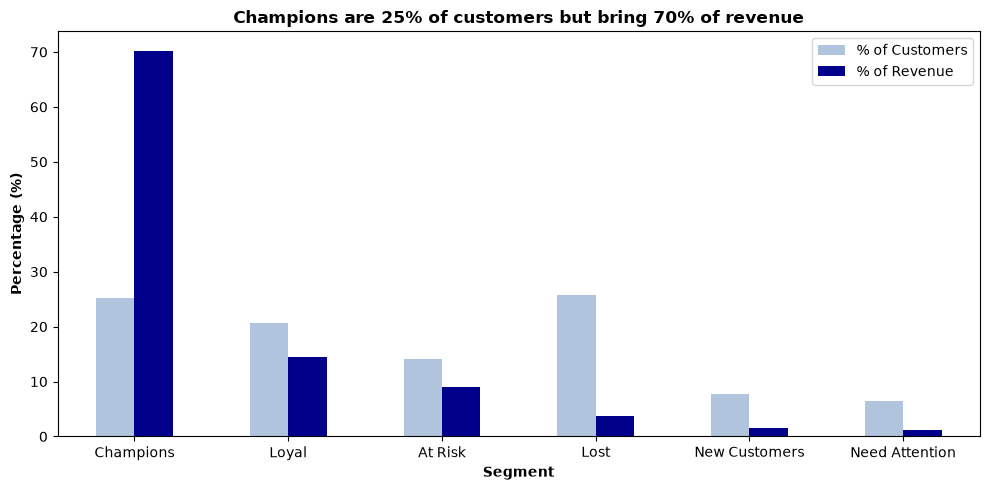

In [52]:
seg_sorted = seg.sort_values('Revenue_%', ascending=False)

seg_sorted[['Customer_%', 'Revenue_%']].plot(kind='bar', figsize=(10, 5),
                                              color=['lightsteelblue', 'darkblue'])
plt.title('Champions are 25% of customers but bring 70% of revenue', fontweight='bold')
plt.xlabel('Segment', fontweight='bold')
plt.ylabel('Percentage (%)', fontweight='bold')
plt.legend(['% of Customers', '% of Revenue'])
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [53]:
# Extra checks to support the recommendations
champ = rfm[rfm['Segment'] == 'Champions'].sort_values('Monetary', ascending=False)
print("Top 50 Champions share of revenue:",
      round(champ['Monetary'].head(50).sum() / rfm['Monetary'].sum() * 100, 1), "%")

at_risk = rfm[rfm['Segment'] == 'At Risk']
print("At Risk - days since last order:", at_risk['Recency'].min(), "to", at_risk['Recency'].max())

new = rfm[rfm['Segment'] == 'New Customers']
print("New Customers - orders:", new['Frequency'].value_counts().to_dict())
first_buy = df.groupby('Customer ID')['InvoiceDate'].min()
recent = first_buy[new['Customer ID']] >= snapshot_date - pd.Timedelta(days=90)
print("New Customers who first bought in last 3 months:", round(recent.mean() * 100, 1), "%")

lost = rfm[rfm['Segment'] == 'Lost']
print("Lost customers with only one order:", round((lost['Frequency'] == 1).mean() * 100, 1), "%")

Top 50 Champions share of revenue: 29.2 %
At Risk - days since last order: 188 to 733
New Customers - orders: {1: 242, 2: 208}
New Customers who first bought in last 3 months: 71.8 %
Lost customers with only one order: 75.0 %


## Recommendations for each segment

| Segment            | Key finding                                                                              | Recommendation                      |
|--------------------|------------------------------------------------------------------------------------------|-------------------------------------|
| **Champions**      | The top 50 Champions alone bring 29% of all revenue.                                     | The business depends heavily on a few buyers. Give them a dedicated contact person, volume discounts and early access to Christmas stock, because losing even one big buyer would hurt. |
| **Loyal**          | Average of 5 orders and £2,006 spent, with the last order about 2.5 months ago.          | Offer volume-based discounts or bundles to grow their order size towards Champion level.                                                                                              |
| **At Risk**        | Last order between 6 months and 2 years ago, but they spent £1.5M in total.              | This is the biggest win-back opportunity. Contact the highest spenders first with a personalised offer.                                                                            |
| **New Customers**  | 72% made their first purchase in the last 3 months; 242 have ordered once and 208 twice. | Welcome them and offer a discount on their next order to build a buying habit.                                                                                                             |
| **Need Attention** | All of them bought about 3 months ago, only once or twice.                               | They are going quiet, so send a reminder or time-limited offer now, before they become Lost.                                                                                          |
| **Lost**           | 75% ordered only once, with an average spend of £411.                                    | Spend very little: one low-cost win-back email at most.                                                                                                                                   |



## Conclusion
After cleaning, the data covers about £16.8M of sales from 5,852 customers in 41 countries.

Key Findings I found:
1. Sales are highest in November and lowest in early spring.
2. About 83% of sales come from the UK.
3. Home decor and Christmas items sell the most.
4. Most orders come in between 10:00 and 15:00.
5. The top 20% of customers bring in about 77% of sales.
6. RFM segmentation shows that Champions (25% of customers) bring 70% of revenue, while 14% of customers are At Risk.
7. Spending and order frequency are very uneven: the average customer spent £2,875 but the median customer spent only £856. Frequency and spending are strongly linked (correlation 0.86).
8. Overseas customers order less often but place bigger orders than UK customers (median £419 vs £299).


My suggestions are to get ready early for the busy autumn months, try to grow sales in nearby European countries, send offers in the late morning, and look after the biggest customers. Retention spending should focus on Champions, and on winning back At Risk customers, who spent £1.5M before going quiet.